# ЛР3: GigaChat-2 (Сбер)

Первый ответ на каждый из 344 запросов: 5 pilot (вне оценки), 39 задач банка и 100 тестовых строк в режимах 0/5/20-shot. Модель запрошена как GigaChat-2; точные версии сервера показаны в summary. История, поиск и инструменты не используются. System/user, temperature=0 и верхний лимит 4096 совпадают с общим протоколом. Значение effective temperature сервер не сообщает — оно не выдумывается.

Run All пересчитывает только анализ сохранённых данных. К API не обращается, код модели повторно не запускает. Результаты Qwen/Yandex и classical baseline были известны до регистрации GigaChat. Прогнозы взяты из командной регистрации; это повторение гипотез по тем же правилам. Выводы отчёта и причины ошибок формулируют участники.

In [1]:
from pathlib import Path
import sys,json,csv,html
from IPython.display import display,HTML,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'gigachat_runner.py').exists())
sys.path.insert(0,str(ROOT/'scripts'))
from analyze_gigachat import analyze
summary=analyze()
OUT=ROOT/'analysis/gigachat'
def show_json(name): print(json.dumps(json.loads((OUT/name).read_text(encoding='utf-8')),ensure_ascii=False,indent=2))
def show_csv(name):
    with (OUT/name).open(encoding='utf-8-sig',newline='') as f:rows=list(csv.DictReader(f))
    keys=list(rows[0]);display(HTML('<table><tr>'+''.join('<th>'+html.escape(k)+'</th>' for k in keys)+'</tr>'+''.join('<tr>'+''.join('<td>'+html.escape(str(r[k]))+'</td>' for k in keys)+'</tr>' for r in rows)+'</table>'))
def figure(name):display(Image(filename=str(OUT/'figures'/name)))
show_json('summary.json')

{
  "responses": 344,
  "pilot": 5,
  "main": 39,
  "classification": 300,
  "model_versions_returned": [
    "GigaChat-2:2.0.28.2"
  ],
  "auto_ABF": {
    "accuracy": 0.4583333333333333,
    "ci_low": 0.25,
    "ci_high": 0.6666666666666666
  },
  "auto_ABF_n": 24,
  "code_pass_at_1": 0.0,
  "code_metrics_match": 0,
  "strict_format_errors": 12,
  "hypotheses_status": {
    "H5": "insufficient_data",
    "H10": "confirm",
    "H12": "reject"
  },
  "overall_39_accuracy": null,
  "manual_review": {
    "B": {
      "n_required": 8,
      "n_paired_scores": 0,
      "kappa": null,
      "status": "pending"
    },
    "C": {
      "n_required": 7,
      "n_paired_scores": 0,
      "kappa": null,
      "status": "pending"
    },
    "D": {
      "n_required": 8,
      "n_paired_scores": 0,
      "flag_agreement": {
        "leakage": {
          "n": 0,
          "kappa": null,
          "agreement": null
        },
        "test_tuning": {
          "n": 0,
          "kappa": null,
    

## Протокол и расходы

Параметры/прогнозы до генераций: docs/gigachat_registration.json, commit 9b810f0. Pilot: 4/5 ответов ожидаемого формата; P04 с JSON и кодом вне JSON сохранён и не повторялся. После пилота параметры и промпты не менялись. В качестве доступа выбран поддерживаемый legacy endpoint: новый api.giga.chat в этом окружении не завершил TLS-подключение, OAuth и прежний адрес работают. CA официальные, TLS-проверка включена; системное хранилище не менялось.

Freemium-квота достаточна, покупок не было. Для сравнения с другими моделями применяется опубликованная эквивалентная цена пакета Lite: 1300 рублей / 20 млн токенов, включая НДС, проверено 19.11.2026. Это условная цена использованных токенов, не фактический платёж и не цена покупки минимального пакета. Usage total_tokens учитывается один раз. Источник: https://developers.sber.ru/docs/ru/gigachat/tariffs/individual-tariffs .

У Сбера prompt_tokens уже исключает precached_prompt_tokens; кэш не тарифицируется. Поэтому расходы считаются по total_tokens, а полный объём входа/выхода и бесплатный кэш показываются отдельно. Кэш префикса не переносит историю решения других задач: в каждый запрос передаются только общий system и один user. Источник: https://developers.sber.ru/docs/ru/gigachat/guides/counting-tokens .

{
  "python": "3.11.4",
  "platform": "Windows-10-10.0.26200-SP0",
  "packages": {
    "numpy": "2.3.5",
    "scipy": "1.16.3",
    "scikit-learn": "1.7.2",
    "matplotlib": "3.10.8",
    "requests": "2.32.3",
    "nbformat": "5.10.4",
    "nbclient": "0.10.2"
  }
}


stage,n,api_cost_estimate_rub,latency_s,billable_input_tokens,cached_input_tokens,output_tokens,mean_latency_s,mean_billable_tokens,mean_full_tokens
pilot,5,0.08995999999999998,3.6134835000048042,1016,210,368,0.7226967000009609,276.8,318.8
main,39,0.619905,47.88046830000894,3929,7311,5608,1.2277043153848446,244.53846153846155,432.0
zero,100,0.7977449999999999,56.22736100000111,8134,24047,4139,0.5622736100000111,122.73,363.2
five,100,1.00503,68.05740859999423,9795,59986,5667,0.6805740859999423,154.62,754.48
twenty,100,1.440790000000001,76.31028110002808,16261,164620,5905,0.7631028110002808,221.66,1867.86


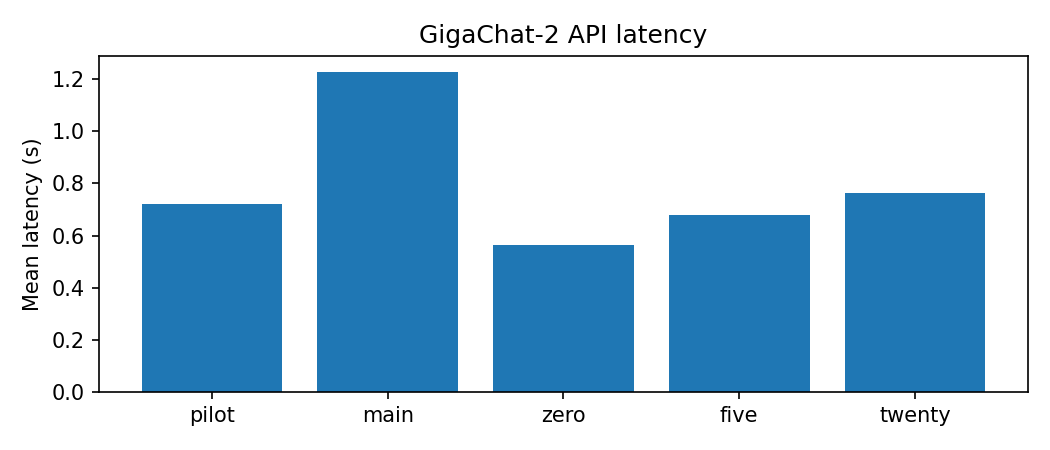

In [2]:
show_json('environment.json')
show_csv('costs.csv')
figure('runtime.png')

## Автоматическая оценка A/B/F

24 задачи: численный допуск банка; B — только вердикт. Обоснования B, C и методология D требуют двух независимых людей. Неразбираемый ответ считается ошибкой. Снимается только одно внешнее Markdown-ограждение по общему правилу; дополнительный текст, JSON-дроби и неверные типы не исправляются.

95% bootstrap CI: 1000 ресэмплов, seed=42. На восьми задачах интервалы грубые; [1,1] или [0,0] не гарантируют качество на новых задачах. Общая accuracy 39 задач до ручной проверки не заявляется.

type,n,accuracy,ci_low,ci_high
A,8,0.0,0.0,0.0
B,8,0.875,0.625,1.0
F,8,0.5,0.125,0.875


task_id,type,parsed,answer,correct,confidence,format_error,cost_rub
A01,A,True,0.32,False,100,,0.017484999999999997
A02,A,True,0.09,False,80,,0.01547
A03,A,True,0.693,False,90,,0.021124999999999998
A04,A,True,1.5,False,100,,0.00663
A05,A,True,0.3823596,False,100,,0.011439999999999999
A06,A,False,,False,,invalid_json,0.016509999999999997
A07,A,True,2,False,80,,0.0104
A08,A,True,0.75,False,90,,0.0104
B01,B,True,False,True,100,,0.006109999999999999
B02,B,True,False,True,80,,0.006239999999999999


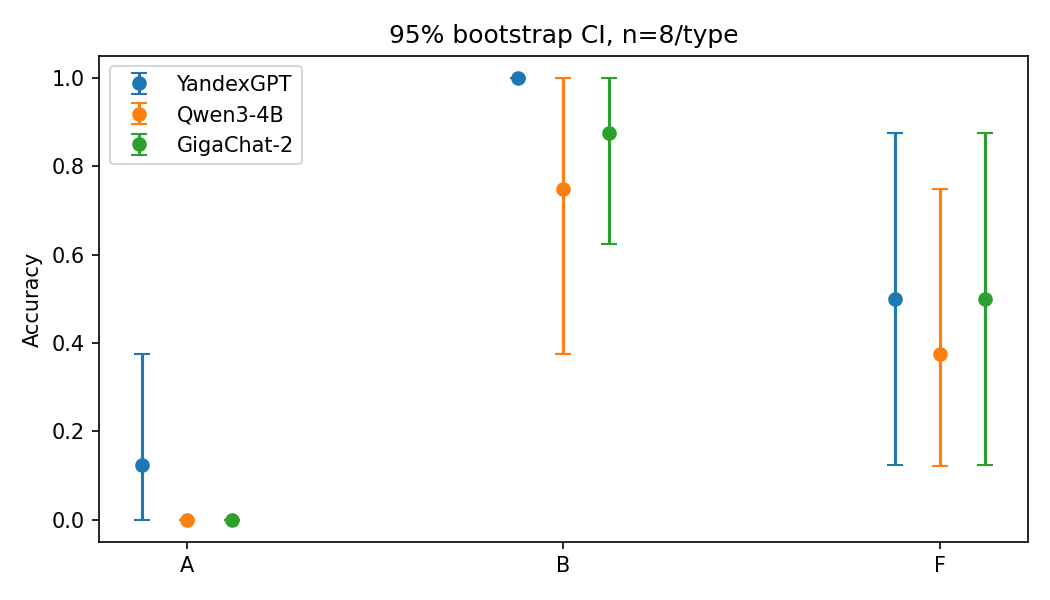

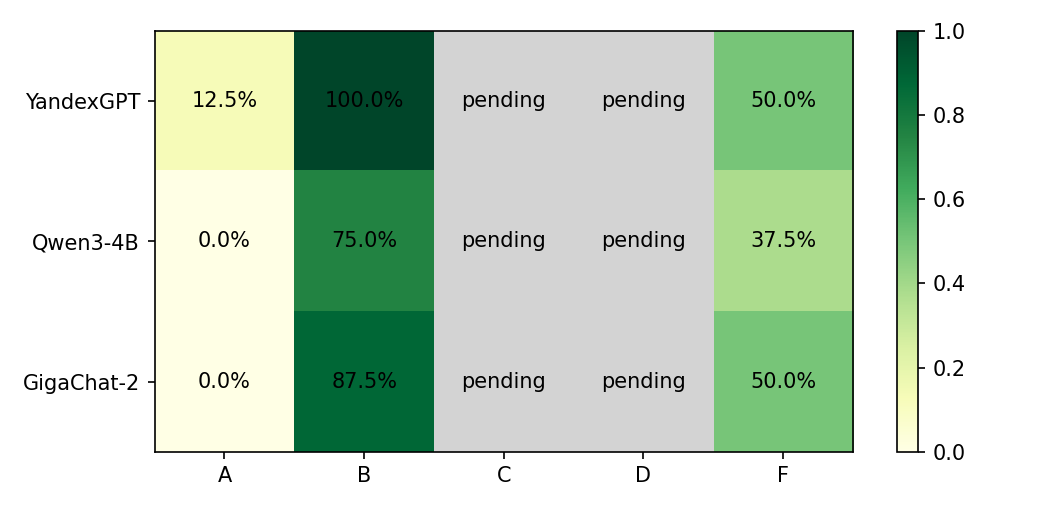

In [3]:
show_csv('type_metrics.csv')
show_csv('automatic_scores.csv')
figure('accuracy_ci.png')
figure('heatmap.png')

## Парное сравнение доступных моделей

Точные тесты Макнемара на совпадающих 24 A/B/F задачах. Семейство из трёх доступных пар Yandex/Qwen/GigaChat с поправкой Holm. Это исследовательские сравнения; четвёртая модель DeepSeek ещё не имеет здесь полного прогона. Проверки относятся к первичным ответам и принятым правилам формата.

{
  "family": "Three available models, 24 A/B/F tasks; exploratory comparisons",
  "results": [
    {
      "first": "YandexGPT",
      "second": "Qwen3-4B",
      "n": 24,
      "first_only_correct": 4,
      "second_only_correct": 0,
      "p_exact": 0.125,
      "p_holm": 0.375,
      "significant_05": false
    },
    {
      "first": "YandexGPT",
      "second": "GigaChat-2",
      "n": 24,
      "first_only_correct": 2,
      "second_only_correct": 0,
      "p_exact": 0.5,
      "p_holm": 1,
      "significant_05": false
    },
    {
      "first": "Qwen3-4B",
      "second": "GigaChat-2",
      "n": 24,
      "first_only_correct": 0,
      "second_only_correct": 2,
      "p_exact": 0.5,
      "p_holm": 1,
      "significant_05": false
    }
  ]
}


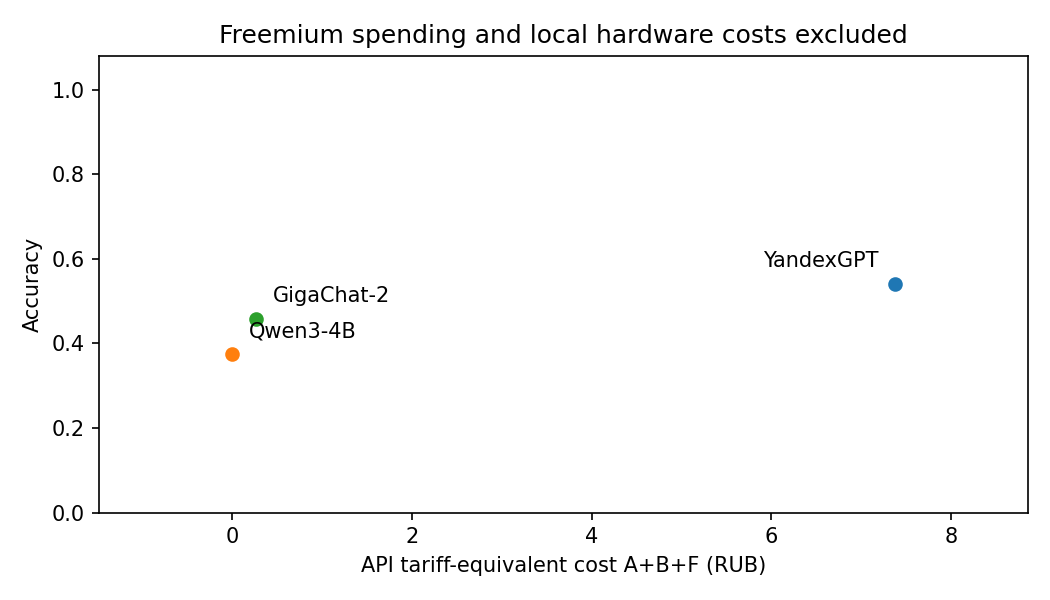

In [4]:
show_json('paired_comparisons.json')
figure('cost_accuracy.png')

## H5: основное сравнение не меняется

В исходной регистрации выбраны YandexGPT vs Qwen3-4B. Это сравнение сохранено. Дополнительно, после просмотра результатов других моделей, рассчитано GigaChat vs Qwen — оно явно вторичное. Статистика gap_A−gap_B, парный bootstrap внутри типов A/B. Модельный размер смешан с обучением, квантованием и режимом; причинный эффект размера не измеряется.

{
  "statistic_gap_A_minus_gap_B": -0.125,
  "ci_low": -0.5,
  "ci_high": 0.25,
  "decision": "insufficient_data",
  "n_A": 8,
  "n_B": 8,
  "seed": 42,
  "bootstrap_iterations": 1000,
  "comparison": "Primary: YandexGPT vs Qwen3-4B, unchanged from local experiment",
  "secondary_gigachat_vs_qwen": {
    "statistic_gap_A_minus_gap_B": -0.125,
    "ci_low": -0.375,
    "ci_high": 0.0,
    "decision": "reject",
    "n_A": 8,
    "n_B": 8,
    "seed": 42,
    "bootstrap_iterations": 1000
  }
}


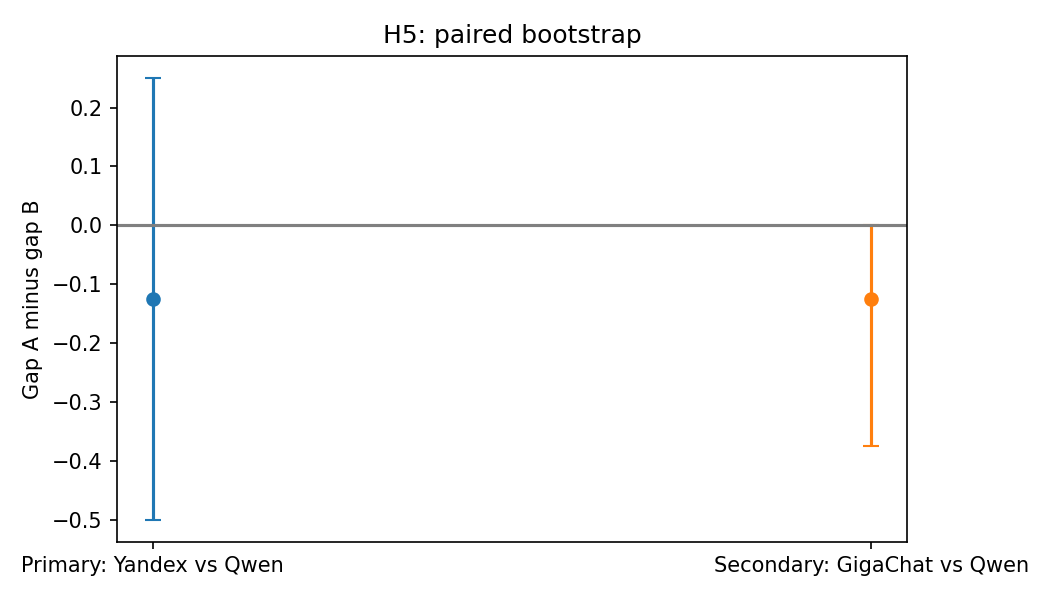

In [5]:
hypotheses=json.loads((OUT/'hypotheses.json').read_text(encoding='utf-8'))
print(json.dumps(hypotheses['H5'],ensure_ascii=False,indent=2))
figure('h5_gap.png')

## H10: уверенность

A+B+F, только разбираемые ответы с доступной confidence; coverage и полная accuracy показаны отдельно. Направление определяется mean(confidence/100−correct), ECE с 5 bins измеряет абсолютную ошибку калибровки. 1000 кластерных bootstrap с сохранением пар F, seed=42; границы 2.5/97.5%. Статус confirm при нижней границе >0, reject при верхней ≤0, иначе insufficient_data.

{
  "n_total": 24,
  "n_valid": 22,
  "coverage": 0.9166666666666666,
  "mean_confidence": 0.9272727272727272,
  "accuracy_on_valid": 0.5,
  "full_denominator_accuracy": 0.4583333333333333,
  "gap": 0.4272727272727273,
  "ci_low": 0.21248511904761908,
  "ci_high": 0.6432022727272727,
  "ece": 0.42727272727272725,
  "decision": "confirm",
  "bins": [
    {
      "bin_low": 0.0,
      "bin_high": 0.2,
      "n": 0,
      "mean_confidence": null,
      "accuracy": null
    },
    {
      "bin_low": 0.2,
      "bin_high": 0.4,
      "n": 0,
      "mean_confidence": null,
      "accuracy": null
    },
    {
      "bin_low": 0.4,
      "bin_high": 0.6,
      "n": 0,
      "mean_confidence": null,
      "accuracy": null
    },
    {
      "bin_low": 0.6,
      "bin_high": 0.8,
      "n": 0,
      "mean_confidence": null,
      "accuracy": null
    },
    {
      "bin_low": 0.8,
      "bin_high": 1.0,
      "n": 22,
      "mean_confidence": 0.9272727272727272,
      "accuracy": 0.5
    }
  ]
}

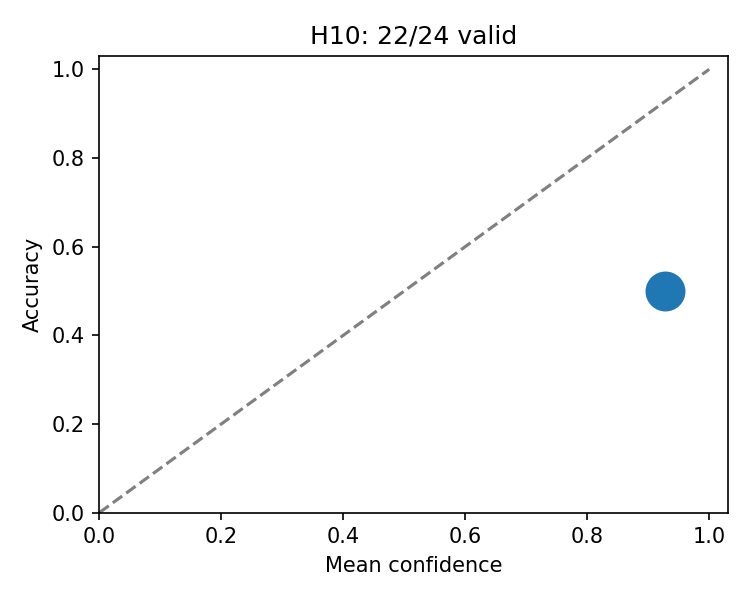

In [6]:
print(json.dumps(hypotheses['H10'],ensure_ascii=False,indent=2))
figure('reliability.png')

## E и H12: классификация

Общие 100 тестовых строк, 6 признаков; train5 вложен в train20. Метки E: 1=malignant, 0=benign, обратно исходной sklearn-кодировке; D08 сохраняет исходную. Отказы и невалидные ответы получают -1 и считаются ошибкой для истинного класса; явные insufficient_data и остальные ошибки формата считаются раздельно. У классических методов zero-shot нет.

Основная метрика F1 класса 1; дополнительно BA и константа. H12: delta=F1_GigaChat−F1_LR. Для 5-shot нижняя односторонняя 95% граница >−0.05 подтверждает не меньшее качество; для 20-shot верхняя <0 подтверждает проигрыш. Парный bootstrap использует одинаковые тестовые строки. Все интервалы условны на единственные фиксированные train5/train20.

model,shots,f1_minority,balanced_accuracy,accuracy,coverage,abstentions,explicit_refusals,other_unscored
GigaChat-2,0,0.5401459854014599,0.5,0.37,1.0,0,0,0
GigaChat-2,5,0.6115702479338843,0.626984126984127,0.53,1.0,0,0,0
GigaChat-2,20,0.8192771084337349,0.8642213642213643,0.85,1.0,0,0,0
LogisticRegression,5,0.8043478260869565,0.8571428571428572,0.82,1.0,0,0,0
LogisticRegression,20,0.9117647058823529,0.9189189189189189,0.94,1.0,0,0,0
GaussianNB,5,0.8043478260869565,0.8571428571428572,0.82,1.0,0,0,0
GaussianNB,20,0.8181818181818182,0.848991848991849,0.88,1.0,0,0,0
constant_majority,0,0.0,0.5,0.63,1.0,0,0,0


[
  {
    "model": "GigaChat-2",
    "shots": 0,
    "f1_minority": 0.5401459854014599,
    "balanced_accuracy": 0.5,
    "accuracy": 0.37,
    "coverage": 1.0,
    "abstentions": 0,
    "ci": {
      "f1_minority": [
        0.43719242125984253,
        0.6394557823129252
      ],
      "balanced_accuracy": [
        0.5,
        0.5
      ],
      "accuracy": [
        0.27975000000000005,
        0.47
      ]
    },
    "explicit_refusals": 0,
    "other_unscored": 0
  },
  {
    "model": "GigaChat-2",
    "shots": 5,
    "f1_minority": 0.6115702479338843,
    "balanced_accuracy": 0.626984126984127,
    "accuracy": 0.53,
    "coverage": 1.0,
    "abstentions": 0,
    "ci": {
      "f1_minority": [
        0.5,
        0.7096774193548387
      ],
      "balanced_accuracy": [
        0.5737704918032787,
        0.685192652329749
      ],
      "accuracy": [
        0.43,
        0.63
      ]
    },
    "explicit_refusals": 0,
    "other_unscored": 0
  },
  {
    "model": "GigaChat-2",

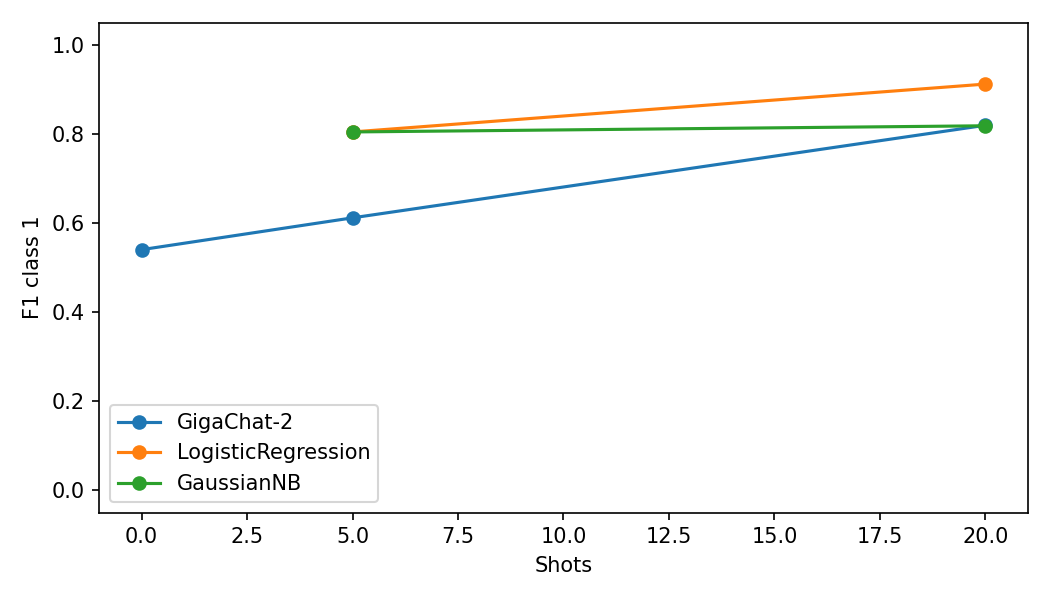

{
  "decision": "reject",
  "comparisons": [
    {
      "shots": 5,
      "delta_f1_llm_minus_lr": -0.19277757815307228,
      "one_sided_95_lower": -0.25363048334358507,
      "one_sided_95_upper": -0.13967070043426183,
      "decision": "reject"
    },
    {
      "shots": 20,
      "delta_f1_llm_minus_lr": -0.09248759744861801,
      "one_sided_95_lower": -0.16803774094757704,
      "one_sided_95_upper": -0.015306584980651988,
      "decision": "confirm"
    }
  ]
}


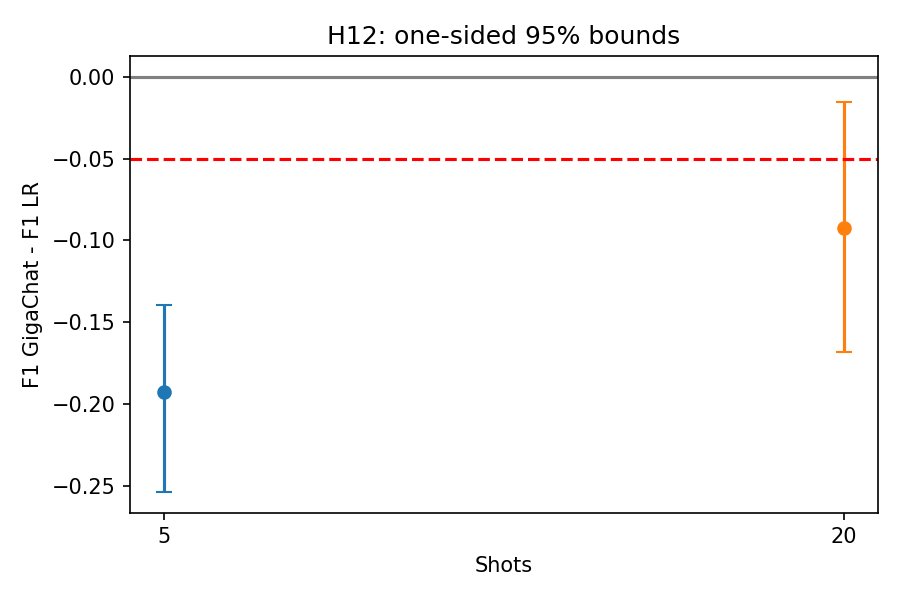

In [7]:
show_csv('classification_metrics.csv')
show_json('classification_metrics.json')
figure('classification_f1.png')
print(json.dumps(hypotheses['H12'],ensure_ascii=False,indent=2))
figure('h12_delta.png')

## C/D: исходные ответы

Ниже все ответы без исправлений. В D все восемь первичных ответов нарушили формат JSON; основной end-to-end pass@1 равен 0. Код, присутствующий вне правильного answer, не засчитывается задним числом. Для понимания технического качества выполнена отдельная post-hoc диагностика: точные подстроки fenced/triple-quoted блоков, с offsets и hashes, без правок. Она не изменяет первичные оценки.

Код просмотрен технически и выполнен в отдельных процессах с очищенным окружением. Это не ОС-контейнер и не две независимые человеческие оценки. Диагностические запускаемость, формат stdout, совпадение чисел и методологические замечания разделены; близкое число не доказывает верную метрику (например, D01 использует accuracy под именем balanced_accuracy).

In [8]:
rows=[json.loads(s) for s in (ROOT/'results/models/gigachat/gigachat-2-v1/responses.jsonl').read_text(encoding='utf-8').splitlines()]
tasks={r['id']:r for r in [json.loads(s) for s in (ROOT/'data/tasks.jsonl').read_text(encoding='utf-8').splitlines()]}
def pre(v):return '<pre style="white-space:pre-wrap">'+html.escape(v if isinstance(v,str) else json.dumps(v,ensure_ascii=False,indent=2))+'</pre>'
for r in rows:
    if r['stage']=='main' and r['task_id'][0] in 'CD':
        raw=r['raw_response']['provider_response']['choices'][0]['message']['content']
        display(HTML('<h3>'+r['task_id']+'</h3>'+pre(tasks[r['task_id']]['text_ru'])+pre(raw)))
        if r['task_id'].startswith('D'):
            for suffix in ['stdout.txt','stderr.txt']:
                p=OUT/'diagnostic_code_execution'/(r['task_id']+'.'+suffix)
                display(HTML('<b>Вторичная диагностика: '+suffix+'</b>'+pre(p.read_text(encoding='utf-8'))))
show_json('code_execution.json')
show_json('diagnostic_code_execution.json')

[
  {
    "task_id": "D01",
    "source_sha256": null,
    "exit_code": null,
    "pass_at_1": false,
    "output_is_json": false,
    "metrics_match_reference": false,
    "metrics": null,
    "stderr": "",
    "status": "invalid_primary_response_format",
    "format_error": "invalid_json",
    "methodology_review": "pending_two_independent_reviewers"
  },
  {
    "task_id": "D02",
    "source_sha256": null,
    "exit_code": null,
    "pass_at_1": false,
    "output_is_json": false,
    "metrics_match_reference": false,
    "metrics": null,
    "stderr": "",
    "status": "invalid_primary_response_format",
    "format_error": "invalid_json",
    "methodology_review": "pending_two_independent_reviewers"
  },
  {
    "task_id": "D03",
    "source_sha256": null,
    "exit_code": null,
    "pass_at_1": false,
    "output_is_json": false,
    "metrics_match_reference": false,
    "metrics": null,
    "stderr": "",
    "status": "invalid_primary_response_format",
    "format_error": "invali

## Материалы для участников

review/ содержит эталоны, рубрики и две пустые независимые формы. Для слепой проверки перемешать ответы разных моделей; ключ соответствия не передавать проверяющим. После заполнения считаются kappa и статусы, пропуски не заменяются нулями. Финальный разбор пяти ошибок и собственные выводы остаются участникам согласно PDF.

Ограничения для обсуждения: малый банк, публичный датасет, фиксированные few-shot примеры, разные режимы провайдеров, влияние форматных ошибок, post-hoc характер диагностики D. Ниже первые пять автоматических ошибок без отбора по удобному выводу; student_analysis оставлено пустым.

In [9]:
show_json('error_examples.json')
show_json('review_status.json')
show_json('provenance.json')

[
  {
    "task_id": "A01",
    "prompt": "Дефект имеют 2% деталей. Датчик срабатывает на 96% дефектных и на 4% исправных деталей. Найдите вероятность дефекта при срабатывании датчика. Ответ дайте долей от 0 до 1.",
    "raw_response": "{\"answer\": 0.32, \"explanation\": \"Используем формулу Байеса. Пусть P(D) — вероятность дефекта, P(S|D) — вероятность срабатывания датчика при дефекте, P(S|!D) — вероятность ложного срабатывания, P(!D) — вероятность отсутствия дефекта. Тогда искомая вероятность дефекта при срабатывании датчика равна P(D|S) = (P(S|D)*P(D)) / ((P(S|D)*P(D)) + (P(S|!D)*P(!D))). Подставляем известные значения: P(D)=0.02, P(S|D)=0.96, P(S|!D)=0.04, P(!D)=0.98. Получаем P(D|S) = (0.96*0.02) / ((0.96*0.02)+(0.04*0.98)) ≈ 0.32.\", \"confidence\": 100}",
    "reference": {
      "answer": 0.3287671232876712,
      "solution_ru": "P(D|+) = 0.02*0.96 / (0.02*0.96 + 0.98*0.04) = 24/73."
    },
    "student_analysis": ""
  },
  {
    "task_id": "A02",
    "prompt": "В узле дерева 